# 03. 조건부 Edge - 가위바위보 승부 판정 (문제 풀이)
`03_conditional_edge.ipynb`의 점검 문제를 푼다. 지금까지는 `score` 하나의 값만 보고 분기했지만, 이번에는 `player`와 `computer` **두 값을 비교**해서 분기하는 조건부 Edge를 만든다. 가위바위보 승부를 판정하는 Graph이다.

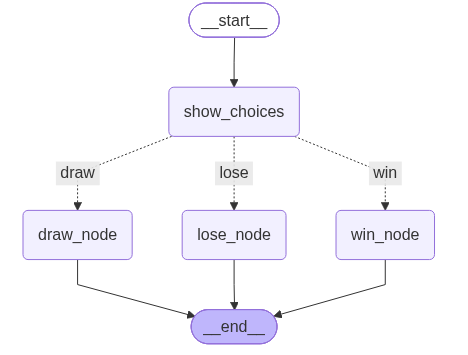

## 요구사항 재확인
- State에는 `player`, `computer`, `result` 세 필드가 있다(`player`, `computer`는 `"가위"`, `"바위"`, `"보"` 중 하나).
- Routing 함수는 `player`와 `computer`를 비교해 `"win"`, `"lose"`, `"draw"` 중 하나를 반환한다.
- 가위는 보를 이기고, 바위는 가위를 이기고, 보는 바위를 이긴다.
- 경우의 수는 3×3 = 9가지이지만, "이기는 조합"만 집합으로 정의하면 if문 하나로 줄일 수 있다.

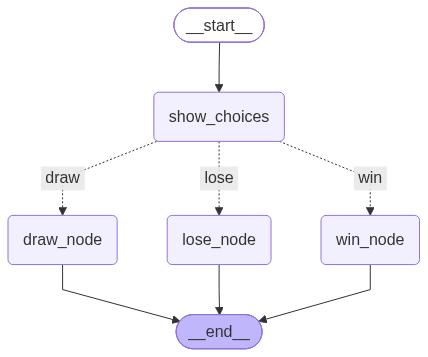

In [1]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

# State에 두 플레이어의 선택과 결과를 저장할 수 있도록 TypedDict 정의하기
class RPSState(TypedDict):
    player: str
    computer: str
    result: str

# Node 정의
def show_choices(state: RPSState) -> dict:
    print(f"실행 Node: show_choices (player={state['player']}, computer={state['computer']})")
    return {}  # 값을 바꾸지 않고 그대로 다음 분기로 넘긴다.


# "player가 computer를 이기는 조합"만 집합으로 정의해 비교를 단순화한다.
WINNING_COMBOS = {("가위", "보"), ("바위", "가위"), ("보", "바위")}

# 결과를 판단하는 조건 분기 함수 정의
def route_judge(state: RPSState) -> str:
    pair = (state["player"], state["computer"])
    if state["player"] == state["computer"]:
        return "draw"  
    return "win" if pair in WINNING_COMBOS else "lose"

# 승리 결과에 해당하는 Node 함수
def win_node(state: RPSState) -> dict:
    print("실행 Node: win_node")
    return {"result": "승리"}

# 패배 결과에 해당하는 Node 함수
def lose_node(state: RPSState) -> dict:
    print("실행 Node: lose_node")
    return {"result": "패배"}

# 무승부 결과에 해당하는 Node 함수
def draw_node(state: RPSState) -> dict:
    print("실행 Node: draw_node")
    return {"result": "무승부"}

# Graph builder 생성
builder = StateGraph(RPSState)

# Node 추가
builder.add_node("show_choices", show_choices)
builder.add_node("win_node", win_node)
builder.add_node("lose_node", lose_node)
builder.add_node("draw_node", draw_node)

# START Edge 연결
builder.add_edge(START, "show_choices")

# 조건 분기 Edge 연결, 
# win -> win_node, lose -> lose_node, draw -> draw_node
builder.add_conditional_edges(
    "show_choices", # 조건분기가 일어나는 Node
    route_judge,  # 조건 분기 함수
    {"win": "win_node", "lose": "lose_node", "draw": "draw_node"},  # 조건 분기 결과에 따른 다음 Node 연결
)

# 승리/패배/무승부 Node를 END Node로 연결
builder.add_edge("win_node", END)
builder.add_edge("lose_node", END)
builder.add_edge("draw_node", END)

# Graph 컴파일
graph = builder.compile()
graph

## 그래프 시각화

In [2]:
# from IPython.display import Image, display

# # PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
# try:
#     display(Image(graph.get_graph().draw_mermaid_png()))
# except Exception as exc:
#     print("PNG 시각화 불가:", type(exc).__name__)
#     print(graph.get_graph().draw_mermaid())

## 자가 점검용 테스트
문제에서 제시한 입력·기대값 표를 그대로 검증한다.

In [ ]:
cases = [
    ("가위", "보", "승리"),
    ("가위", "바위", "패배"),
    ("가위", "가위", "무승부"),
    ("바위", "가위", "승리"),
    ("보", "바위", "승리"),
    ("보", "가위", "패배"),
]

# 테스트 케이스 실행
for player, computer, expected in cases:
    print(f"\n입력: player={player}, computer={computer}")
    result = graph.invoke({"player": player, "computer": computer, "result": "미정"})
    print("최종 State:", result)

    # 테스트용
    assert result["result"] == expected
print("\n모든 케이스 통과")


입력: player=가위, computer=보
실행 Node: show_choices (player=가위, computer=보)
실행 Node: win_node
최종 State: {'player': '가위', 'computer': '보', 'result': '승리'}

입력: player=가위, computer=바위
실행 Node: show_choices (player=가위, computer=바위)
실행 Node: lose_node
최종 State: {'player': '가위', 'computer': '바위', 'result': '패배'}

입력: player=가위, computer=가위
실행 Node: show_choices (player=가위, computer=가위)
실행 Node: draw_node
최종 State: {'player': '가위', 'computer': '가위', 'result': '무승부'}

입력: player=바위, computer=가위
실행 Node: show_choices (player=바위, computer=가위)
실행 Node: win_node
최종 State: {'player': '바위', 'computer': '가위', 'result': '승리'}

입력: player=보, computer=바위
실행 Node: show_choices (player=보, computer=바위)
실행 Node: win_node
최종 State: {'player': '보', 'computer': '바위', 'result': '승리'}

입력: player=보, computer=가위
실행 Node: show_choices (player=보, computer=가위)
실행 Node: lose_node
최종 State: {'player': '보', 'computer': '가위', 'result': '패배'}

모든 케이스 통과


## 보너스: 랜덤 컴퓨터와 대결
자가 점검 테스트와는 별도로, 컴퓨터가 매번 무작위로 내는 버전을 실행해본다. 실행할 때마다 결과가 달라질 수 있다.

In [ ]:
import random

player_choice = "바위"  # 원하는 값으로 바꿔본다.
computer_choice = random.choice(["가위", "바위", "보"])
bonus_result = graph.invoke({"player": player_choice, "computer": computer_choice, "result": "미정"})
print("최종 State:", bonus_result)

실행 Node: show_choices (player=바위, computer=바위)
실행 Node: draw_node
최종 State: {'player': '바위', 'computer': '바위', 'result': '무승부'}


## 해설
- `player == computer`를 가장 먼저 검사해야 무승부를 다른 경로와 혼동하지 않는다.
- 9가지 조합을 모두 if문으로 나열하지 않고, "이기는 조합" 3가지만 집합(`WINNING_COMBOS`)으로 정의하면 나머지는 자동으로 "lose"가 된다. 조건을 데이터로 표현하면 코드가 짧아지고 조합이 늘어나도 유지보수하기 쉽다.
- Routing 함수가 매핑 딕셔너리에 없는 키를 반환하면 실행 시 오류가 발생한다. 매핑의 키(`"win"`, `"lose"`, `"draw"`)와 Routing 함수의 반환값은 정확히 일치해야 한다.